# Ausgrid Solar Home Data — 2012–2013 Exploration and Hourly Preparation

Explore the local household dataset at `data/raw/Solar home 2012-2013.csv`. The notebook documents source conventions and demonstrates hourly aggregation; a reproducible script writes the three-house hourly CSV and customer-ID mapping. No LSTM is trained here.

In [65]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Locate the existing local CSV without downloading anything.
_candidates = [
    Path("data/raw/Solar home 2012-2013.csv"),
    Path("../data/raw/Solar home 2012-2013.csv"),
]
DATA_PATH = next((path for path in _candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find data/raw/Solar home 2012-2013.csv from this notebook's working directory."
    )

# The first CSV row is a title/instruction; the second row contains field names.
# Preserve literal 'NA' and blanks in Row Quality as distinct quality statuses.
df = pd.read_csv(DATA_PATH, header=1, low_memory=False, keep_default_na=False)
INTERVAL_COLUMNS = [column for column in df.columns if ":" in str(column)]
if len(INTERVAL_COLUMNS) != 48:
    raise ValueError(f"Expected 48 half-hour interval columns; found {len(INTERVAL_COLUMNS)}")

# Parse dates and interval readings, without changing the source file.
df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
for column in INTERVAL_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

DOCUMENTATION_PATH = (
    Path.home()
    / "Downloads/Ausgrid_solar_home_data/Ausgrid solar home electricity data notes (Aug 2014).pdf"
)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Documentation PDF found locally: {DOCUMENTATION_PATH.exists()}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Half-hour columns ({len(INTERVAL_COLUMNS)}): {INTERVAL_COLUMNS}")
display(df.head())

Loaded: /Users/dimpalkava/Stochastic-Game-Theoretic-Optimization-under-uncertain-energy-conditions/data/raw/Solar home 2012-2013.csv
Documentation PDF found locally: True
Shape: 268,557 rows × 54 columns
Half-hour columns (48): ['0:30', '1:00', '1:30', '2:00', '2:30', '3:00', '3:30', '4:00', '4:30', '5:00', '5:30', '6:00', '6:30', '7:00', '7:30', '8:00', '8:30', '9:00', '9:30', '10:00', '10:30', '11:00', '11:30', '12:00', '12:30', '13:00', '13:30', '14:00', '14:30', '15:00', '15:30', '16:00', '16:30', '17:00', '17:30', '18:00', '18:30', '19:00', '19:30', '20:00', '20:30', '21:00', '21:30', '22:00', '22:30', '23:00', '23:30', '0:00']


,Customer,Generator Capacity,Postcode,Consumption Category,date,0:30,1:00,1:30,2:00,2:30,...,20:00,20:30,21:00,21:30,22:00,22:30,23:00,23:30,0:00,Row Quality
0,1,3.78,2076,CL,2012-07-01,1.250,1.250,1.250,1.263,0.131,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.081,
1,1,3.78,2076,GC,2012-07-01,0.855,0.786,0.604,0.544,0.597,...,0.374,0.447,0.549,0.136,0.288,0.181,0.651,0.090,0.068,
2,1,3.78,2076,GG,2012-07-01,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,
3,1,3.78,2076,CL,2012-07-02,1.250,1.250,1.125,0.000,0.925,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.069,
4,1,3.78,2076,GC,2012-07-02,0.309,0.082,0.059,0.097,0.290,...,0.353,0.464,0.229,0.811,0.222,0.306,1.034,0.136,0.067,


## 1. Source documentation and field meanings

The included Ausgrid notes (August 2014) specify:

- **GC — General Consumption:** electricity supplied under the primary tariff, excluding solar generation and controlled-load supply.
- **GG — Gross Generation:** solar-system generation measured separately from household loads.
- **CL — Controlled Load:** consumption on separate off-peak tariffs (controlled-load tariff 1 or 2).
- **Units:** interval readings are **kWh of energy** consumed or generated in each half-hour. Generator Capacity is recorded in **kWp** (kilowatt-peak), not kW output.
- **Interval convention:** labels mark the **end** of each half-hour, e.g. `0:30` covers 00:00–00:30; `1:00` covers 00:30–01:00. The 48 intervals are in local Eastern Standard/Daylight time as applicable.

For household demand, GC alone excludes CL by definition. GC+CL can be considered if the target should include separately metered off-peak usage; retain the components separately during exploration and make that modeling choice explicitly. This notebook only inspects them.

In [66]:
print("Columns and inferred data types:")
display(df.dtypes.rename("dtype").to_frame())

print(f"Date range: {df['date'].min()} through {df['date'].max()}")
print(f"Invalid/unparsed dates: {df['date'].isna().sum():,}")
print(f"Unique customer IDs: {df['Customer'].nunique():,}")
print("Customers by consumption category:")
display(df.groupby("Consumption Category")["Customer"].nunique().rename("unique_customers").to_frame())

missing = df.isna().sum().sort_values(ascending=False)
print("\nActual missing values by column (Row Quality blanks are intentionally preserved):")
display(missing.loc[missing.gt(0)].rename("missing_count").to_frame())

key_columns = ["Customer", "Consumption Category", "date"]
print(f"Duplicate customer/category/date keys: {df.duplicated(key_columns).sum():,}")
print(f"Duplicate full rows: {df.duplicated().sum():,}")
print("Row Quality counts (blank = actual; literal NA = estimated/substitute):")
quality = df["Row Quality"].replace("", "(blank / actual)").value_counts(dropna=False)
display(quality.rename("rows").to_frame())

Columns and inferred data types:


,dtype
Customer,int64
Generator Capacity,float64
Postcode,int64
Consumption Category,str
date,datetime64[us]
0:30,float64
1:00,float64
1:30,float64
2:00,float64
2:30,float64


Date range: 2012-07-01 00:00:00 through 2013-06-30 00:00:00
Invalid/unparsed dates: 0
Unique customer IDs: 300
Customers by consumption category:


,unique_customers
Consumption Category,
CL,138
GC,300
GG,300



Actual missing values by column (Row Quality blanks are intentionally preserved):


,missing_count


Duplicate customer/category/date keys: 0
Duplicate full rows: 0
Row Quality counts (blank = actual; literal NA = estimated/substitute):


,rows
Row Quality,
(blank / actual),268126
NA,431


## 2. Category coverage and customer matching

GC and GG are available for all 300 customers; CL is a separate category and only exists for customers with controlled-load service. Compare date coverage and complete actual-reading availability. A “complete” row here means all 48 interval values are present and `Row Quality` is blank (actual), not an estimate.

In [67]:
actual_mask = df["Row Quality"].eq("") & df[INTERVAL_COLUMNS].notna().all(axis=1)
actual = df.loc[actual_mask].copy()

coverage = (
    df.groupby("Consumption Category")
    .agg(
        rows=("Customer", "size"),
        unique_customers=("Customer", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        unique_dates=("date", "nunique"),
    )
)
coverage["complete_actual_rows"] = actual.groupby("Consumption Category").size()
print("Coverage by category:")
display(coverage)

actual_days = actual.groupby(["Customer", "Consumption Category"])["date"].nunique().unstack(fill_value=0)
print("Distribution of complete actual days per customer/category:")
display(actual_days.apply(lambda column: column.value_counts().sort_index()).fillna(0).astype(int))

# Count fully matching GC/GG customer-days using both customer ID and date.
gc_keys = actual.loc[actual["Consumption Category"].eq("GC"), ["Customer", "date"]]
gg_keys = actual.loc[actual["Consumption Category"].eq("GG"), ["Customer", "date"]]
matched_gc_gg_days = gc_keys.merge(gg_keys, on=["Customer", "date"], how="inner", validate="one_to_one")
matched_days_per_customer = matched_gc_gg_days.groupby("Customer")["date"].nunique()
full_year_customers = matched_days_per_customer[matched_days_per_customer.eq(365)].index.tolist()
print(f"Customer-days with complete actual GC and GG matched by customer + date: {len(matched_gc_gg_days):,}")
print(f"Customers with all 365 days matched and actual for both GC and GG: {len(full_year_customers):,}")
print("First 15 full-year eligible source customer IDs:", full_year_customers[:15])

Coverage by category:


,rows,unique_customers,first_date,last_date,unique_dates,complete_actual_rows
Consumption Category,,,,,,
CL,49719,138,2012-07-01,2013-06-30,365,49717
GC,109419,300,2012-07-01,2013-06-30,365,109136
GG,109419,300,2012-07-01,2013-06-30,365,109273


Distribution of complete actual days per customer/category:


Consumption Category,CL,GC,GG
0,162,0,0
247,0,1,0
284,1,1,1
296,0,1,1
300,3,0,0
305,2,0,0
307,2,0,0
315,0,1,1
317,1,0,0
318,1,0,0


Customer-days with complete actual GC and GG matched by customer + date: 109,135
Customers with all 365 days matched and actual for both GC and GG: 269
First 15 full-year eligible source customer IDs: [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


## 3. Generator capacity and complete-year energy summaries

Generator capacity is provided in kWp. Half-hour interval readings are kWh, so adding all 48 intervals gives daily energy and summing 365 complete, actual days gives a full-year total. Estimated (`NA`) quality-flagged records are excluded here. Category totals are shown only for customers with a full year of actual records in that category.

Generator capacity across customers (kWp):


,capacity_kwp
count,300.00
mean,1.68
std,1.04
min,1.00
25%,1.02
50%,1.50
75%,2.00
max,9.99



Full-year sums using only customers with 365 complete actual days in each category:


,Customer,Generator Capacity,Consumption Category,full_year_actual_kwh
0,1,3.78,CL,2399.317
1,1,3.78,GC,5279.884
2,1,3.78,GG,5115.207
3,3,1.00,CL,296.387
4,3,1.00,GC,1948.262
5,3,1.00,GG,1556.220
6,4,1.00,CL,1536.841
7,4,1.00,GC,3516.346
8,4,1.00,GG,1326.593
9,5,1.00,CL,1459.797



Full-year actual customer counts by category:


,customers
Consumption Category,
CL,126
GC,270
GG,273


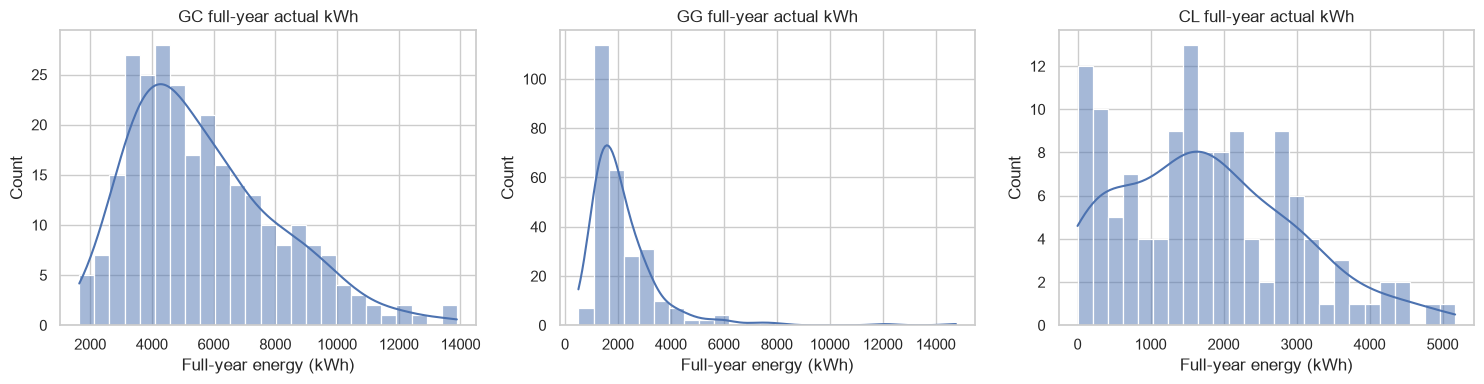

In [68]:
actual["daily_kwh"] = actual[INTERVAL_COLUMNS].sum(axis=1)
actual_day_counts = actual.groupby(["Customer", "Consumption Category"])["date"].nunique()
full_year_pairs = actual_day_counts[actual_day_counts.eq(365)].index
full_year_actual = actual.set_index(["Customer", "Consumption Category"]).loc[
    actual.set_index(["Customer", "Consumption Category"]).index.isin(full_year_pairs)
].reset_index()
customer_category_year = (
    full_year_actual.groupby(["Customer", "Generator Capacity", "Consumption Category"])["daily_kwh"]
    .sum()
    .rename("full_year_actual_kwh")
    .reset_index()
)

capacity_summary = (
    df.drop_duplicates("Customer")["Generator Capacity"]
    .describe()
    .to_frame("capacity_kwp")
)
print("Generator capacity across customers (kWp):")
display(capacity_summary.round(2))
print("\nFull-year sums using only customers with 365 complete actual days in each category:")
display(customer_category_year.head(12))
print("\nFull-year actual customer counts by category:")
display(customer_category_year.groupby("Consumption Category")["Customer"].nunique().rename("customers").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for category, ax in zip(["GC", "GG", "CL"], axes):
    values = customer_category_year.loc[
        customer_category_year["Consumption Category"].eq(category), "full_year_actual_kwh"
    ]
    sns.histplot(values, bins=25, kde=True, ax=ax)
    ax.set_title(f"{category} full-year actual kWh")
    ax.set_xlabel("Full-year energy (kWh)")
plt.tight_layout()
plt.show()

## 4. Example customer-day profile (visualization only)

Show one day for one customer to make the 48 end-labeled half-hour readings concrete. The plot is only an exploratory view; it does not select the final three houses or export transformed records.

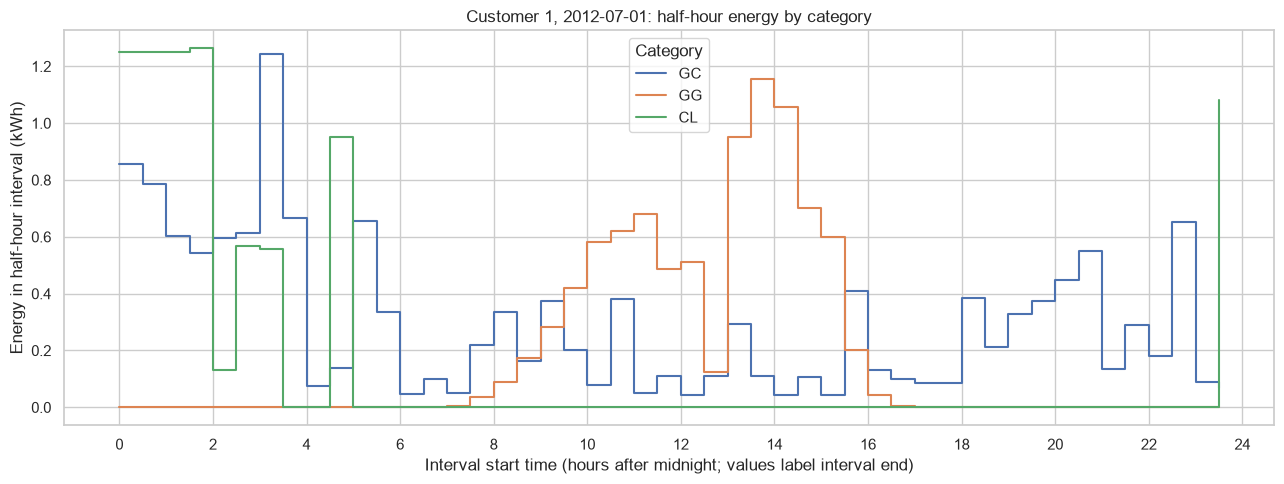

In [69]:
example_customer = int(df["Customer"].dropna().min())
example_date = df["date"].min()
example_rows = actual.loc[
    actual["Customer"].eq(example_customer)
    & actual["date"].eq(example_date)
    & actual["Consumption Category"].isin(["GC", "GG", "CL"])
]
if example_rows.empty:
    print("No fully actual records for the first customer/date; choose another example date.")
else:
    interval_labels = INTERVAL_COLUMNS
    # Labels refer to interval end; x values are elapsed half-hours since midnight.
    elapsed_hours = np.arange(48) / 2
    fig, ax = plt.subplots(figsize=(13, 5))
    for category in ["GC", "GG", "CL"]:
        row = example_rows.loc[example_rows["Consumption Category"].eq(category)]
        if not row.empty:
            ax.step(elapsed_hours, row[interval_labels].iloc[0].to_numpy(dtype=float),
                    where="post", label=category)
    ax.set_title(f"Customer {example_customer}, {example_date.date()}: half-hour energy by category")
    ax.set_xlabel("Interval start time (hours after midnight; values label interval end)")
    ax.set_ylabel("Energy in half-hour interval (kWh)")
    ax.set_xticks(range(0, 25, 2))
    ax.legend(title="Category")
    plt.tight_layout()
    plt.show()

## Findings from this exploration and preparation

- The source has **268,557 rows**, **54 fields** (five descriptor fields, 48 half-hour kWh readings, and `Row Quality`), **300 customers**, and dates from **2012-07-01 to 2013-06-30**.
- It has no duplicate full rows or duplicate `(Customer, Consumption Category, date)` keys. The quality flag is blank for **268,126 actual rows** and `NA` for **431 estimated/substitute rows**; those `NA` flags are preserved as text, not mistaken for missing readings.
- **117 customers** have full-year actual GC, CL, and GG records. The preparation script selects the first three eligible IDs, `1`, `3`, and `4`, mapped to H001–H003. It requires matching categories for every customer and date and excludes estimated rows.
- The PDF documents interval energy as kWh, half-hour-ending labels, local EST/EDT timestamps, and generator capacity in kWp. Therefore, output uses `generator_capacity_kwp` (not kW) and naive local wall-clock timestamps (no UTC offset is supplied in this daily file).
- Hourly demand is `(GC first half-hour + GC second half-hour) + (CL first half-hour + CL second half-hour)`. Solar generation is the corresponding pairwise sum of GG only. Solar is not added to or subtracted from household demand.
- The hourly panel and house-ID mapping are saved under `data/processed/`. The script does not train an LSTM or create next-hour target columns.

## 5. Interval-to-hour convention

Each source reading is kWh for the **half-hour ending at the label**. Thus each ordinary hour's energy is the sum of its two half-hours: `0:30 + 1:00` for 00:00–01:00, `1:30 + 2:00` for 01:00–02:00, and so on. The final daily interval `0:00` pairs with `23:30` for the hour beginning 23:00.

The dataset uses local EST/EDT labels but supplies fixed 48 intervals per date and no UTC offsets. The prepared `timestamp` is therefore a timezone-naive local wall-clock timestamp; do not interpret it as UTC. These are kWh sums, not averages and not kW conversions. Generator capacity remains in its documented kWp units.

In [70]:
# A small formula check for the first ordinary hour; no dataset is written.
example_gc = actual.loc[
    actual["Consumption Category"].eq("GC")
    & actual["Customer"].eq(example_customer)
    & actual["date"].eq(example_date)
].iloc[0]
example_gg = actual.loc[
    actual["Consumption Category"].eq("GG")
    & actual["Customer"].eq(example_customer)
    & actual["date"].eq(example_date)
].iloc[0]

interval_pair = ["0:30", "1:00"]
print(f"Example: customer {example_customer}, {example_date.date()}, hour starting 00:00")
print(f"GC hourly energy = {interval_pair[0]} + {interval_pair[1]} = "
      f"{example_gc[interval_pair].sum():.3f} kWh")
print(f"GG hourly energy = {interval_pair[0]} + {interval_pair[1]} = "
      f"{example_gg[interval_pair].sum():.3f} kWh")
print("Exploration complete: no LSTM was built and no transformed dataset was saved.")

Example: customer 1, 2012-07-01, hour starting 00:00
GC hourly energy = 0:30 + 1:00 = 1.641 kWh
GG hourly energy = 0:30 + 1:00 = 0.000 kWh
Exploration complete: no LSTM was built and no transformed dataset was saved.


## 6. Demonstrate half-hour-to-hour summation

For each standard hour, add the two consecutive half-hour **kWh** intervals. The first hour is `0:30 + 1:00`; the hour starting 01:00 is `1:30 + 2:00`, and so on. These are sums of energy, not averages or conversions to kW. The final daily interval `0:00` is the half-hour ending at midnight and is paired with that date’s `23:30` for the hour starting 23:00. This cell demonstrates the conversion for one actual customer-day only; it does not create or save a transformed dataset.

In [71]:
# Use category/customer/date as the key so GC and GG never get mixed across houses.
example_day = actual.loc[
    actual["Customer"].eq(example_customer)
    & actual["date"].eq(example_date)
    & actual["Consumption Category"].isin(["GC", "GG"])
].copy()

# Pair the readings in chronological order. Each pair's values are kWh in
# adjacent half-hours, so summing gives kWh for one hour.
hourly_interval_pairs = [
    (INTERVAL_COLUMNS[index], INTERVAL_COLUMNS[index + 1])
    for index in range(0, 48, 2)
]
hourly_rows = []
for _, source_row in example_day.iterrows():
    for hour_index, (first_interval, second_interval) in enumerate(hourly_interval_pairs):
        hourly_rows.append(
            {
                "Customer": int(source_row["Customer"]),
                "date": source_row["date"],
                "Consumption Category": source_row["Consumption Category"],
                "hour_start": f"{hour_index:02d}:00",
                "first_half_hour_end": first_interval,
                "second_half_hour_end": second_interval,
                "hourly_energy_kwh": source_row[first_interval] + source_row[second_interval],
            }
        )

hourly_example = pd.DataFrame(hourly_rows)
display(hourly_example.head(6))
print("Final hour check (23:30 and next-day 0:00 interval labels):")
display(hourly_example.tail(2))

,Customer,date,Consumption Category,hour_start,first_half_hour_end,second_half_hour_end,hourly_energy_kwh
0,1,2012-07-01,GC,00:00,0:30,1:00,1.641
1,1,2012-07-01,GC,01:00,1:30,2:00,1.148
2,1,2012-07-01,GC,02:00,2:30,3:00,1.209
3,1,2012-07-01,GC,03:00,3:30,4:00,1.910
4,1,2012-07-01,GC,04:00,4:30,5:00,0.216
5,1,2012-07-01,GC,05:00,5:30,6:00,0.994


Final hour check (23:30 and next-day 0:00 interval labels):


,Customer,date,Consumption Category,hour_start,first_half_hour_end,second_half_hour_end,hourly_energy_kwh
46,1,2012-07-01,GG,22:00,22:30,23:00,0.0
47,1,2012-07-01,GG,23:00,23:30,0:00,0.0


## 7. Prepared three-house hourly panel

The separate script `src/data/prepare_solar_home_hourly.py` selects houses only if all 365 dates have complete actual GC, CL, and GG records; joins categories by source customer and date; sums half-hour kWh pairs; and writes a clean panel plus a reversible ID map. This section inspects those outputs only—no forecasting model is trained.

In [72]:
from pathlib import Path

_hourly_candidates = [
    Path("data/processed/three_house_hourly_lstm_ready.csv"),
    Path("../data/processed/three_house_hourly_lstm_ready.csv"),
]
HOURLY_DATA_PATH = next((path for path in _hourly_candidates if path.exists()), None)
if HOURLY_DATA_PATH is None:
    raise FileNotFoundError("Run src/data/prepare_solar_home_hourly.py first.")

_mapping_candidates = [
    Path("data/processed/customer_id_mapping.csv"),
    Path("../data/processed/customer_id_mapping.csv"),
]
MAPPING_PATH = next((path for path in _mapping_candidates if path.exists()), None)
if MAPPING_PATH is None:
    raise FileNotFoundError("House ID mapping CSV was not found.")

hourly_panel = pd.read_csv(HOURLY_DATA_PATH, parse_dates=["timestamp"])
house_mapping = pd.read_csv(MAPPING_PATH)
assert len(hourly_panel) == 3 * 365 * 24
assert not hourly_panel.duplicated(["house_id", "timestamp"]).any()
assert hourly_panel[["total_demand_kwh", "solar_generation_kwh"]].notna().all().all()
assert hourly_panel.groupby("house_id").size().eq(365 * 24).all()

print(f"Prepared panel: {hourly_panel.shape[0]:,} rows × {hourly_panel.shape[1]} columns")
print("Per-house hourly row counts:")
display(hourly_panel.groupby("house_id").size().rename("rows").to_frame())
print("House ID mapping:")
display(house_mapping)
print("Hourly data sample:")
display(hourly_panel.groupby("house_id").head(3))

Prepared panel: 26,280 rows × 8 columns
Per-house hourly row counts:


,rows
house_id,
H001,8760
H002,8760
H003,8760


House ID mapping:


,house_id,source_customer_id,postcode,generator_capacity_kwp,selection_criteria
0,H001,1,2076,3.78,"365 complete actual days for GC, CL, and GG"
1,H002,3,2263,1.00,"365 complete actual days for GC, CL, and GG"
2,H003,4,2220,1.00,"365 complete actual days for GC, CL, and GG"


Hourly data sample:


,house_id,timestamp,total_demand_kwh,solar_generation_kwh,generator_capacity_kwp,hour,day_of_week,month
0,H001,2012-07-01 00:00:00,4.141,0.0,3.78,0,6,7
1,H001,2012-07-01 01:00:00,3.661,0.0,3.78,1,6,7
2,H001,2012-07-01 02:00:00,1.909,0.0,3.78,2,6,7
8760,H002,2012-07-01 00:00:00,1.892,0.0,1.00,0,6,7
8761,H002,2012-07-01 01:00:00,1.419,0.0,1.00,1,6,7
8762,H002,2012-07-01 02:00:00,0.115,0.0,1.00,2,6,7
17520,H003,2012-07-01 00:00:00,0.168,0.0,1.00,0,6,7
17521,H003,2012-07-01 01:00:00,4.074,0.0,1.00,1,6,7
17522,H003,2012-07-01 02:00:00,0.961,0.0,1.00,2,6,7
